In [1]:
# 1. LIBRERÍAS
import numpy as np
import os # sirve para interactuar con el sistema de archivos y directorios del sistema operativo
from PIL import Image # con esto importamos la librería de imágenes que sirve para abrir, manipular y guardar imágenes en diferentes formatos
import matplotlib.pyplot as plt

In [2]:
# 2. FUNCIÓN (AUTOMÁTICA POR CARPETAS)
# Esta función recorre las carpetas de un directorio, carga las imágenes, las redimensiona y normaliza, 
# y asigna etiquetas basadas en el nombre de la carpeta.
def cargar_dataset(base_dir, img_size=(150,150)):
    imagenes = []
    etiquetas = []

    for clase in os.listdir(base_dir):
        ruta_clase = os.path.join(base_dir, clase)

        if os.path.isdir(ruta_clase):
            for archivo in os.listdir(ruta_clase):
                if archivo.lower().endswith(('.jpg','.jpeg','.png')): # Verifica que el archivo sea una imagen para evitar errores  

                    ruta = os.path.join(ruta_clase, archivo)

                    img = Image.open(ruta) # Carga la imagen
                    img = img.resize(img_size) # Redimensiona la imagen al tamaño especificado
                    img = np.array(img) / 255.0 #  Normaliza los valores de píxeles a [0,1], 250 es debido a que los valores de píxeles van de 0 a 255, y al dividirlo por 255.0 se obtiene un rango de 0 a 1

                    imagenes.append(img)
                    etiquetas.append(clase)

    return np.array(imagenes), np.array(etiquetas) # finalmente guarda todas las imagenes en una lista y todas las etiquetas en otra

In [3]:
# 3. Lectura de la ruta
base_dir = r"Cars_Body_Type/train"

## Fuente del dataset y clases utilizadas

Se utiliza el dataset de Kaggle disponible en la ruta `ademboukhris/cars-body-type-cropped`, cuya página se titula **Car Body Types Images Dataset**.

[Consultar el dataset en Kaggle](https://www.kaggle.com/datasets/ademboukhris/cars-body-type-cropped)

El problema es de clasificación multiclase: a partir de una imagen de un vehículo, se busca identificar su tipo de carrocería entre siete categorías. No se utilizan los ejemplos prohibidos en el taller: MNIST, bananos verdes frente a maduros ni Fashion-MNIST.

### Imágenes cargadas para el desarrollo

Se cargan las imágenes de la carpeta `Cars_Body_Type/train`. La salida del conteo por clase registra:

| Clase | Número de imágenes |
| --- | ---: |
| Convertible | 811 |
| Coupe | 721 |
| Hatchback | 701 |
| Pick-Up | 759 |
| SUV | 847 |
| Sedan | 729 |
| VAN | 782 |
| **Total** | **5350** |

Todas las clases superan el mínimo de 200 imágenes exigido. Estas 5350 imágenes corresponden a la carpeta cargada, no al total de imágenes publicado en Kaggle. Después se dividen en entrenamiento, validación y prueba dentro del notebook.

Las etiquetas representan distintos tipos de carrocería. Sin embargo, algunas categorías pueden resultar visualmente similares según el ángulo, el recorte o el vehículo. Los errores de clasificación mostrados al final deben tenerse en cuenta al analizar esta dificultad; no basta con tener nombres de clases distintos para garantizar que todas las imágenes sean fáciles de diferenciar.

In [4]:
# 4. CARGAR DATOS
X, Y = cargar_dataset(base_dir)

print("Shape:", X.shape)
print("Ejemplo etiquetas:", Y[:10])

# Nos arroja que son 5350 imagenes, 150x 150 pixeles, y 3 canales (RGB) por ser imagenes a color

Shape: (5350, 150, 150, 3)
Ejemplo etiquetas: ['Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible'
 'Convertible' 'Convertible' 'Convertible' 'Convertible' 'Convertible']


In [5]:
# Conteo de imágenes cargadas por clase
clases, conteos = np.unique(Y, return_counts=True)
for clase, conteo in zip(clases, conteos):
    print(f"{clase}: {conteo} imágenes")

print("Cumple mínimo de 200 por clase:", bool(np.all(conteos >= 200)))

Convertible: 811 imágenes
Coupe: 721 imágenes
Hatchback: 701 imágenes
Pick-Up: 759 imágenes
SUV: 847 imágenes
Sedan: 729 imágenes
VAN: 782 imágenes
Cumple mínimo de 200 por clase: True


In [6]:
# 5. CODIFICAR ETIQUETAS
# En este proceso se utiliza LabelEncoder para convertir las etiquetas de texto en números enteros, 
# lo que es necesario para el entrenamiento del modelo. Es decir, cada categoría queda con un número asignado
from sklearn.preprocessing import LabelEncoder

labelencoder = LabelEncoder()
Y = labelencoder.fit_transform(Y)

print("Clases:", labelencoder.classes_)

Clases: ['Convertible' 'Coupe' 'Hatchback' 'Pick-Up' 'SUV' 'Sedan' 'VAN']


In [7]:
# 6. SPLIT
# Aquí se divide el conjunto de datos en entrenamiento y prueba utilizando train_test_split de sklearn,
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [8]:
# Separación de entrenamiento y validación
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

## Preparación de las imágenes

Para entrenar el modelo, se prepararon las imágenes mediante los siguientes pasos:

- **Carga y asignación de etiquetas:** se recorren las subcarpetas de `train` y se utiliza el nombre de cada carpeta como etiqueta. Esto permite relacionar cada imagen con su tipo de carrocería sin etiquetarla manualmente.

- **Redimensionado a 150 × 150 píxeles:** todas las imágenes se llevan al mismo tamaño para que tengan dimensiones compatibles con la entrada de la red. Este tamaño busca un equilibrio entre el detalle visual y el costo de procesamiento.

- **Normalización:** se dividen los valores de los píxeles entre 255 para pasarlos del rango de 0 a 255 al rango de 0 a 1. Esto mantiene una escala de entrada uniforme y puede facilitar la optimización durante el entrenamiento.

- **Codificación de etiquetas:** se utiliza `LabelEncoder` para convertir los nombres de las clases en etiquetas numéricas que puedan utilizarse al entrenar el modelo.

- **Separación de datos:** primero se reserva el 20 % de las 5350 imágenes como conjunto de prueba (`X_test`, `y_test`): 1070 imágenes. Después se toma el 20 % de las 4280 imágenes restantes para validación (`X_val`, `y_val`): 856 imágenes. Así, el reparto final es de 3424 imágenes para entrenamiento (64 % del total), 856 para validación (16 %) y 1070 para prueba (20 %). Ambas divisiones usan `stratify` para mantener aproximadamente la proporción de las clases y `random_state=42` para fijar la división al repetirla con los mismos datos y su mismo orden. El conjunto de entrenamiento se utiliza para ajustar los pesos; el de validación se utiliza durante el entrenamiento del modelo optimizado para supervisar su desempeño y controlar los callbacks; el de prueba se utiliza para evaluar ambos modelos por separado. En el modelo base no se incluyó validación durante `fit()`.

## MODELO BASE

In [9]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, MaxPooling2D, Dropout, RandomFlip, RandomRotation, RandomZoom, GlobalAveragePooling2D
import tensorflow as tf

tf.random.set_seed(3)
np.random.seed(3)

modelo = Sequential()

# Primera capa convolucional para extraer características básicas.
modelo.add(Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)))
modelo.add(MaxPooling2D(2,2))

# Convierte los mapas de características en un vector.
modelo.add(Flatten())

# Desactiva aleatoriamente algunas conexiones durante el entrenamiento.
modelo.add(Dropout(0.2))

# Capa densa para realizar la clasificación.
modelo.add(Dense(32, activation='relu'))

# Clasificación en las siete categorías.
modelo.add(Dense(7, activation='softmax'))

modelo.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = modelo.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=8
)

I0000 00:00:1793719086.026981    2023 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793719086.305462    2023 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793719088.533626    2023 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not

Epoch 1/20


I0000 00:00:1793719095.904897    2435 service.cc:153] XLA service 0x77d420032340 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793719095.904938    2435 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4050 Laptop GPU, Compute Capability 8.9 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793719095.944479    2435 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793719096.166521    2435 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1793719096.204952    2435 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1305__.22


 23/428 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.2283 - loss: 3.3493

I0000 00:00:1793719100.859838    2435 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


428/428 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.1595 - loss: 2.0220
Epoch 2/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9453
Epoch 3/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9445
Epoch 4/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 5/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 6/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9443
Epoch 7/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.1583 - loss: 1.9443
Epoch 8/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9443
Epoch 9/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 10/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 11/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.1583 - loss: 1.9444
Epoch 12/20
428/428 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy

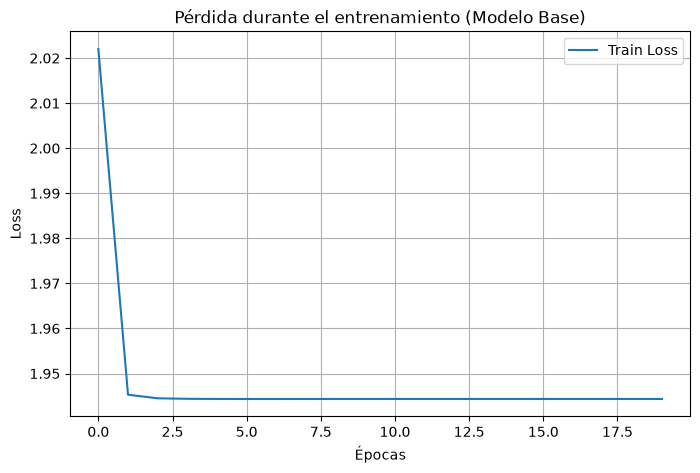

In [10]:
# Gráfica de la pérdida durante el entrenamiento del modelo base.
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

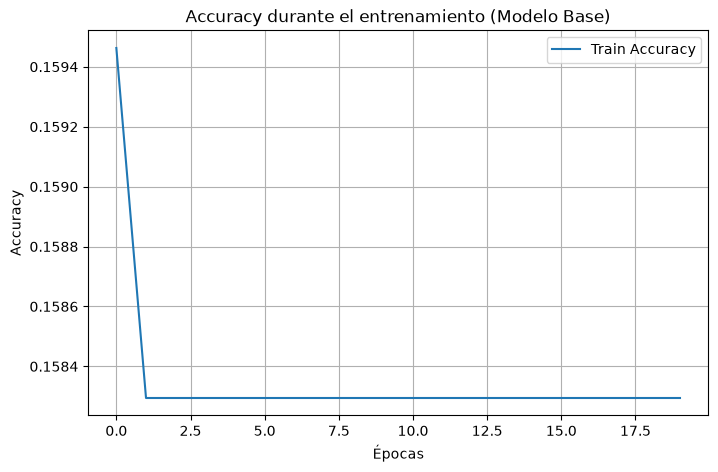

In [11]:
# Gráfica del accuracy durante el entrenamiento del modelo base.
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Base)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [12]:
# Métricas de evaluación para el modelo base utilizando accuracy_score y f1_score de sklearn.
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

107/107 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step
===== TRAIN =====
Accuracy: 0.1582943925233645
F1-score: 0.04326553744208954

===== TEST =====
Accuracy: 0.15794392523364487
F1-score: 0.04308720478528811


## Interpretación de los resultados del modelo base

Después de entrenar durante 20 épocas, la evaluación guardada en el notebook muestra estos resultados:

| Conjunto | Accuracy | F1-score ponderado |
| --- | ---: | ---: |
| Entrenamiento | 0.98569 | 0.98565 |
| Prueba | 0.57196 | 0.57962 |

El modelo clasifica correctamente aproximadamente el 98.57 % de las imágenes de entrenamiento, pero solo el 57.20 % de las imágenes de prueba. La diferencia es de aproximadamente 41.37 puntos porcentuales.

Esta diferencia indica sobreajuste: el modelo obtiene un desempeño alto con las imágenes usadas para entrenar, pero generaliza mucho peor a las imágenes de prueba. Por eso, una accuracy alta en entrenamiento no basta para afirmar que el modelo funciona bien.

El F1-score ponderado de prueba es 0.57962. Esta métrica combina la precisión y la exhaustividad de cada clase y pondera el resultado por la cantidad de ejemplos de cada clase. Se usa como complemento de la accuracy, no como un porcentaje de aciertos.

Estos resultados se toman como referencia para comparar el modelo base con el modelo optimizado.

## MODELO CNN OPTIMIZADO

In [13]:
# AUMENTO DE DATOS
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_generator = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True,
    fill_mode='nearest'
)

# CALLBACKS
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15,
                                     restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                         patience=6, min_lr=1e-5, verbose=1)
]

In [14]:
# Configuración del modelo optimizado con capas adicionales de convolución, normalización y dropout para mejorar el rendimiento.
from tensorflow.keras import layers
from tensorflow.keras import regularizers

modelo_opt = Sequential()

# Bloque 1 - 2 capas convolucionales de 32 neuronas
modelo_opt.add(Conv2D(32, (3,3), padding='same', input_shape=(150,150,3)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(32, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 2 - 2 capas convolucionales de 64 neuronas
modelo_opt.add(Conv2D(64, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(64, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 3 - 2 capas convolucionales de 128 neuronas
modelo_opt.add(Conv2D(128, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(128, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

# Bloque 4 - 2 capas convolucionales de 256 neuronas
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))
modelo_opt.add(Dropout(0.1))   # único Dropout convolucional

# Bloque 5
modelo_opt.add(Conv2D(256, (3,3), padding='same'))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(MaxPooling2D(2,2))

modelo_opt.add(Flatten())   # de vuelta a Flatten: conserva información espacial

# Fully connected
modelo_opt.add(Dense(256, kernel_regularizer=regularizers.l2(0.001)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Dropout(0.5))

modelo_opt.add(Dense(128, kernel_regularizer=regularizers.l2(0.001)))
modelo_opt.add(layers.BatchNormalization())
modelo_opt.add(layers.Activation('relu'))
modelo_opt.add(Dropout(0.4))

modelo_opt.add(Dense(7, activation='softmax'))

modelo_opt.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

/home/julian/entornos/trabajo-ia-gpu/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [15]:
history_opt = modelo_opt.fit(
    train_generator.flow(X_train, y_train, batch_size=32),
    validation_data=(X_val, y_val),
    epochs=90,
    callbacks=callbacks
)

Epoch 1/90


I0000 00:00:1793719167.413328    2023 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1793719175.457226    2434 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_46328__.132
I0000 00:00:1793719182.499616    2434 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


107/107 ━━━━━━━━━━━━━━━━━━━━ 54s 189ms/step - accuracy: 0.2158 - loss: 2.8007 - val_accuracy: 0.1589 - val_loss: 2.8161 - learning_rate: 0.0010
Epoch 2/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 11s 100ms/step - accuracy: 0.3151 - loss: 2.4522 - val_accuracy: 0.1460 - val_loss: 3.2214 - learning_rate: 0.0010
Epoch 3/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.4267 - loss: 2.1291 - val_accuracy: 0.3049 - val_loss: 2.4047 - learning_rate: 0.0010
Epoch 4/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 94ms/step - accuracy: 0.4775 - loss: 1.9026 - val_accuracy: 0.2593 - val_loss: 3.2252 - learning_rate: 0.0010
Epoch 5/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 11s 101ms/step - accuracy: 0.5558 - loss: 1.6725 - val_accuracy: 0.5946 - val_loss: 1.5502 - learning_rate: 0.0010
Epoch 6/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 10s 92ms/step - accuracy: 0.6019 - loss: 1.5526 - val_accuracy: 0.6332 - val_loss: 1.4438 - learning_rate: 0.0010
Epoch 7/90
107/107 ━━━━━━━━━━━━━━━━━━━━ 11s 99ms/step - accuracy: 0.6387 - loss: 1.4

## Cambios implementados en el modelo optimizado

Se mantiene el esquema general de una CNN: extracción de características con convoluciones y pooling, aplanado con `Flatten` y clasificación mediante capas densas. No es una copia idéntica del modelo base: además de agregar capas, se cambian la cantidad de unidades de las capas densas y otros ajustes del entrenamiento.

### Aumento de datos

Se utiliza `ImageDataGenerator` para generar variaciones de las imágenes de entrenamiento: rotaciones de hasta 10 grados, zoom del 10 %, desplazamientos horizontales y verticales de hasta el 5 % y volteo horizontal aleatorio. Los espacios que aparecen al transformar las imágenes se rellenan con el modo `nearest`.

Estas transformaciones se aplican mediante `train_generator.flow(X_train, y_train, batch_size=32)` durante el entrenamiento. Buscan que el modelo aprenda con distintas posiciones y escalas del vehículo. No se agregan fotografías originales nuevas ni se guardan automáticamente estas variaciones como archivos. La validación y la prueba no pasan por este generador.

### Arquitectura y regularización

- **Convoluciones:** el modelo pasa de una a nueve capas convolucionales, organizadas en cinco bloques, con filtros de 32, 64, 128 y 256. Buscan aprender representaciones visuales más complejas.
- **Pooling:** cada bloque incluye `MaxPooling2D` para reducir las dimensiones espaciales de sus mapas de características.
- **BatchNormalization:** se incorpora después de las convoluciones y de las dos capas densas ocultas para normalizar las activaciones y ayudar a estabilizar el entrenamiento.
- **Flatten:** convierte los mapas de características en un vector, conservando sus valores y su orden para conectarlos con las capas densas. No mantiene una estructura bidimensional explícita.
- **Capas fully connected:** se utilizan dos capas densas ocultas de 256 y 128 unidades, en lugar de la única capa oculta de 32 del modelo base. La salida conserva siete unidades con `softmax`, una por clase.
- **Dropout:** se aplican tasas de 0.1, 0.5 y 0.4 para desactivar aleatoriamente parte de las activaciones durante el entrenamiento y buscar reducir el sobreajuste.
- **Regularización L2:** las dos capas densas ocultas usan un factor de 0.001 para penalizar pesos grandes.

### Configuración del entrenamiento

Se utiliza Adam con una tasa de aprendizaje inicial de 0.001 y la función de pérdida `sparse_categorical_crossentropy`, compatible con las etiquetas enteras de las siete clases. El entrenamiento se configura con lotes de 32 imágenes y un máximo de 90 épocas.

`EarlyStopping` supervisa `val_loss`, con una paciencia de 15 épocas y restauración de los mejores pesos. `ReduceLROnPlateau` reduce a la mitad la tasa de aprendizaje cuando `val_loss` no mejora durante seis épocas, sin bajarla de 0.00001. Ambos callbacks utilizan el conjunto de validación, no el de prueba.

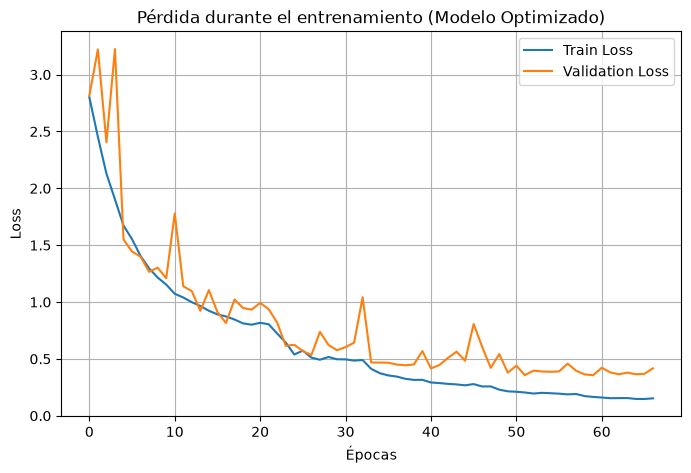

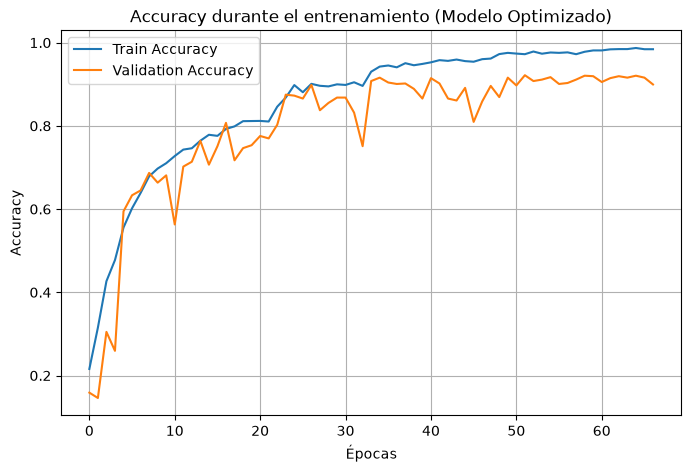

In [16]:
import matplotlib.pyplot as plt

# =========================
# LOSS
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['loss'], label='Train Loss')
plt.plot(history_opt.history['val_loss'], label='Validation Loss')
plt.title('Pérdida durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

# =========================
# ACCURACY
# =========================
plt.figure(figsize=(8,5))
plt.plot(history_opt.history['accuracy'], label='Train Accuracy')
plt.plot(history_opt.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy durante el entrenamiento (Modelo Optimizado)')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

In [17]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# =========================
# PREDICCIONES TRAIN
# =========================
y_train_pred = modelo_opt.predict(X_train)
y_train_pred_classes = np.argmax(y_train_pred, axis=1)

# =========================
# PREDICCIONES TEST
# =========================
y_test_pred = modelo_opt.predict(X_test)
y_test_pred_classes = np.argmax(y_test_pred, axis=1)

# =========================
# MÉTRICAS
# =========================

# TRAIN
train_acc = accuracy_score(y_train, y_train_pred_classes)
train_f1  = f1_score(y_train, y_train_pred_classes, average='weighted')

# TEST
test_acc = accuracy_score(y_test, y_test_pred_classes)
test_f1  = f1_score(y_test, y_test_pred_classes, average='weighted')

# =========================
# RESULTADOS
# =========================
print("===== TRAIN =====")
print("Accuracy:", train_acc)
print("F1-score:", train_f1)

print("\n===== TEST =====")
print("Accuracy:", test_acc)
print("F1-score:", test_f1)

107/107 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step
34/34 ━━━━━━━━━━━━━━━━━━━━ 5s 160ms/step
===== TRAIN =====
Accuracy: 0.9985397196261683
F1-score: 0.998539724713172

===== TEST =====
Accuracy: 0.9205607476635514
F1-score: 0.9204315276247208


## Evaluación del modelo optimizado y comparación con el modelo base

Las evaluaciones guardadas en el notebook muestran los siguientes resultados. En ambos casos se utilizan los mismos conjuntos de entrenamiento y prueba.

| Modelo | Accuracy de entrenamiento | F1 ponderado de entrenamiento | Accuracy de prueba | F1 ponderado de prueba |
| --- | ---: | ---: | ---: | ---: |
| Base | 0.98569 | 0.98565 | 0.57196 | 0.57962 |
| Optimizado | 0.99971 | 0.99971 | 0.93178 | 0.93203 |

### Interpretación

El modelo optimizado clasifica correctamente aproximadamente el 93.18 % de las imágenes de prueba, frente al 57.20 % del modelo base. La mejora es de 35.98 puntos porcentuales. El F1-score ponderado de prueba también aumenta, de 0.57962 a 0.93203.

La diferencia entre la accuracy de entrenamiento y la de prueba disminuye de 41.37 puntos porcentuales en el modelo base a 6.79 en el optimizado. Esto indica una mejor generalización en esta evaluación, aunque todavía existe una diferencia entre ambos conjuntos y no se puede afirmar que el sobreajuste haya desaparecido por completo.

Las curvas del modelo optimizado permiten observar la evolución del entrenamiento y de la validación. La salida registra 90 épocas completas y la restauración de los pesos de la época 88, elegida por la menor pérdida de validación (`val_loss`). Por tanto, no se detuvo el entrenamiento antes de llegar al máximo de épocas configurado.

### Selección para el despliegue

Se selecciona el modelo optimizado para el despliegue local porque, entre las dos versiones evaluadas, obtiene mejores resultados de accuracy y F1-score ponderado en el mismo conjunto de prueba. El modelo seleccionado se guarda posteriormente en `modelo_cars.keras`.

La mejora corresponde al conjunto de cambios realizados: aumento de datos, mayor profundidad, normalización, regularización y ajustes del entrenamiento. Como también cambian las épocas y el tamaño del lote, esta comparación no permite atribuir la mejora a una sola capa o técnica. Los resultados corresponden a la ejecución guardada y no garantizan el mismo desempeño en cualquier imagen nueva.

In [18]:
# GUARDAR EL MODELO
modelo_opt.save("modelo_cars_v4.keras")

# GUARDAR EL LABEL ENCODER ya que el modelo solo guarda los pesos, no la información de las clases, 
# por lo que es necesario guardar el label encoder para poder interpretar las predicciones del modelo posteriormente.
import pickle

with open("labelencoder_v4.pkl", "wb") as f:
    pickle.dump(labelencoder, f)

## Despliegue local y predicción de imágenes

El despliegue se carga el modelo optimizado guardado en `modelo_cars.keras` y el codificador de etiquetas de `labelencoder.pkl`

El archivo `.keras` conserva la arquitectura y los pesos del modelo, junto con su configuración de entrenamiento y el estado del optimizador. El codificador se guarda por separado para relacionar los índices numéricos de las predicciones con los nombres de las siete clases.

### Procedimiento de predicción

1. Se recorren las subcarpetas de `Cars_Body_Type/test` para localizar archivos JPG, JPEG y PNG.
2. Cada imagen se convierte a RGB, se redimensiona a 150 × 150 píxeles y sus valores se dividen entre 255, manteniendo la escala de entrada utilizada durante el entrenamiento.
3. Se agrega la dimensión del lote para enviar una imagen al modelo.
4. Se obtiene la salida `softmax` y se selecciona la clase con el valor más alto mediante `argmax`.
5. Se recupera el nombre de la clase con `LabelEncoder` y se compara con la etiqueta deducida del nombre de la carpeta que contiene la imagen.
6. Se registran los resultados de todas las imágenes y se muestran únicamente las clasificadas incorrectamente.

### Resultados de la ejecución guardada

Se procesaron 802 imágenes: 758 se clasificaron correctamente y 44 incorrectamente. La accuracy fue de aproximadamente 94.51 %.

Este resultado corresponde a la carpeta `Cars_Body_Type/test`. No debe confundirse con el 93.18 % obtenido por el modelo optimizado sobre `X_test`, que es el conjunto de 1070 imágenes separado previamente de la carpeta `train`.

La clase con mayor proporción de errores fue Coupe, con 10 errores de 79 imágenes (12.7 %). Hatchback tuvo la mayor cantidad de errores: 11 de 99 imágenes (11.1 %). La confusión más frecuente fue Hatchback clasificado como Sedan, con siete casos. Estos resultados ayudan a localizar dificultades, pero no demuestran por sí solos sus causas.

El valor mostrado como confianza es la salida máxima de `softmax`; no garantiza que la predicción sea correcta. En los ejemplos guardados también aparecen predicciones incorrectas con valores cercanos a 1.

Cargando modelo y label encoder...
Se encontraron 802 imágenes. Procesando...

===== RESUMEN =====
Total: 802 | Aciertos: 733 | Errores: 69
Accuracy: 0.9140

Errores por clase real:
  Convertible: 7/174 errores (4.0%)
  Coupe: 9/79 errores (11.4%)
  Hatchback: 12/99 errores (12.1%)
  Pick-Up: 7/110 errores (6.4%)
  SUV: 14/125 errores (11.2%)
  Sedan: 18/109 errores (16.5%)
  VAN: 2/106 errores (1.9%)

Mostrando 69 de 69 imágenes mal clasificadas...
[Convertible] 00413_Chrysler-Crossfire-Convertible-2008_jpg.rf.c9df456418c955bb6835f088ace41039.jpg → Predicción: Coupe (confianza 0.99)


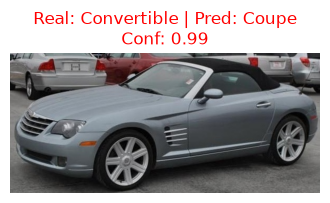

[Convertible] 04796_Ford-Mustang-Convertible-2007_jpg.rf.7d3e7d0c24011ea0bc145b1a9069b00a.jpg → Predicción: Coupe (confianza 0.77)


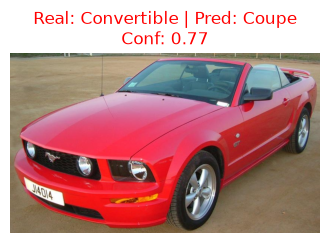

[Convertible] 193_jpg.rf.f2d23a89817ace46c43018640d51be8c.jpg → Predicción: SUV (confianza 0.58)


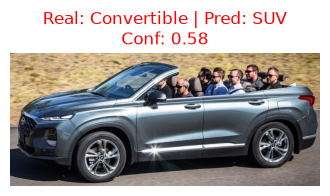

[Convertible] 312_jpg.rf.cc5920af81661f8b525c25802d6cde07.jpg → Predicción: Coupe (confianza 0.73)


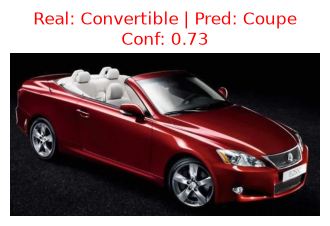

[Convertible] d8149822-66b6-11eb-b835-8c164571e025_jpg.rf.3c1bc58ef3da8aeefac898f7fc382d94.jpg → Predicción: Coupe (confianza 1.00)


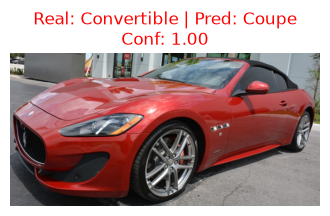

[Convertible] d8149837-66b6-11eb-b9e3-8c164571e025_jpg.rf.b29119e561c8c0b389091f0b12600e2d.jpg → Predicción: Coupe (confianza 0.99)


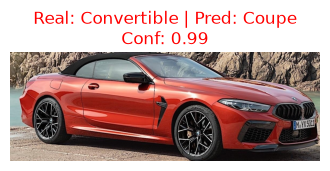

[Convertible] d814bf39-66b6-11eb-a4cb-8c164571e025_jpg.rf.d5ab471ffe435e78c827c476a1438d1f.jpg → Predicción: Coupe (confianza 0.99)


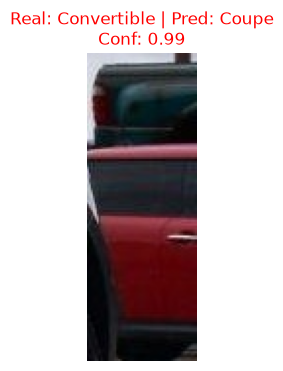

[Coupe] 00787_Infiniti-G-Coupe-IPL-2012_jpg.rf.e79fd1a3e1b7c52451090412ae574615.jpg → Predicción: Sedan (confianza 0.78)


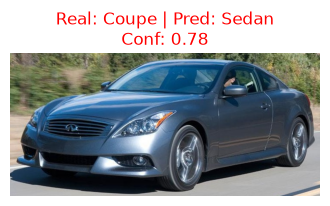

[Coupe] 04428_Audi-TTS-Coupe-2012_jpg.rf.0a3e062d1af241735eae80042466c20b.jpg → Predicción: Convertible (confianza 0.68)


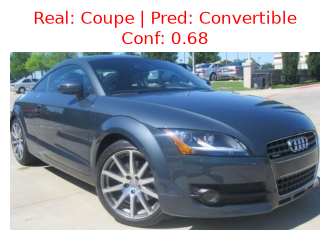

[Coupe] 04510_Aston-Martin-V8-Vantage-Coupe-2012_jpg.rf.9b6422eac00afa2c67b43a6345a6feef.jpg → Predicción: Convertible (confianza 0.99)


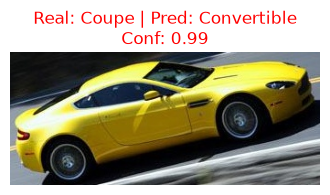

[Coupe] 06845_Audi-TTS-Coupe-2012_jpg.rf.b4ea1b949a092477d7f9d07bfe6c591c.jpg → Predicción: Convertible (confianza 0.84)


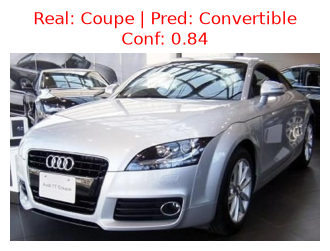

[Coupe] 0ab48d64-66b3-11eb-9141-8c164571e025_jpg.rf.8a42cb30b3b4a2f7b9e13fc793780f46.jpg → Predicción: SUV (confianza 0.94)


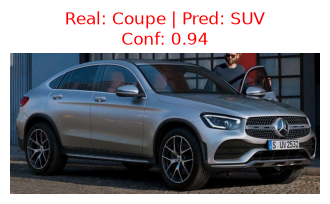

[Coupe] 131_jpg.rf.3e9030e6edd995e58ffe028f02aef995.jpg → Predicción: Convertible (confianza 0.97)


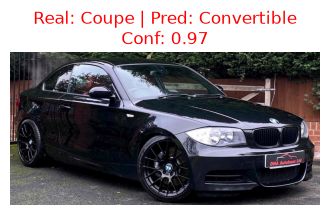

[Coupe] 148_jpg.rf.40cfaa3d6406e02d35a0f8aa54d1ff43.jpg → Predicción: Hatchback (confianza 0.46)


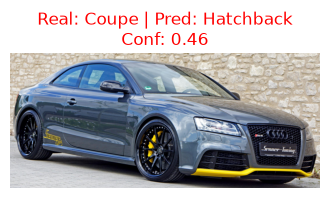

[Coupe] 173_jpg.rf.3f6d26bc2b3a933abfd57a0833704218.jpg → Predicción: Convertible (confianza 0.88)


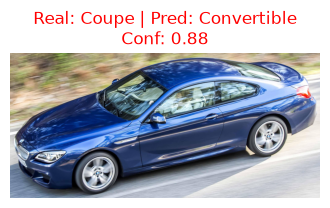

[Coupe] 77_jpg.rf.aee00019f0daef9fc545e1eae5bd81fa.jpg → Predicción: Sedan (confianza 0.96)


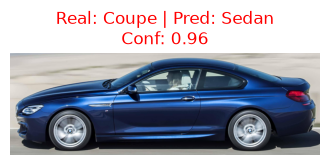

[Hatchback] 00442_Volkswagen-Golf-Hatchback-2012_jpg.rf.3875274cd997830c6fdf7d689419e48b.jpg → Predicción: Convertible (confianza 0.76)


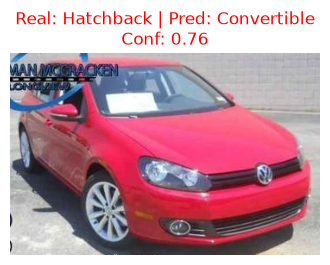

[Hatchback] 03642_Nissan-Juke-Hatchback-2012_jpg.rf.b3bce2dc909301f4d02bbe20155fe812.jpg → Predicción: Convertible (confianza 0.82)


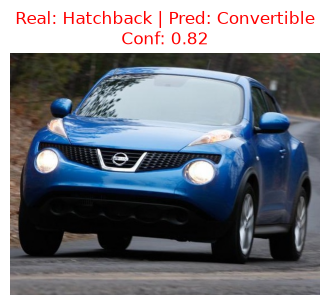

[Hatchback] 03922_Volkswagen-Golf-Hatchback-2012_jpg.rf.2e9ee3a8c1872cf6c360de7f7fa05cb9.jpg → Predicción: Sedan (confianza 0.93)


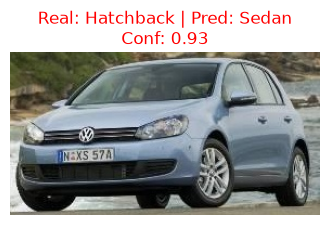

[Hatchback] 05939_Nissan-Juke-Hatchback-2012_jpg.rf.161fa5292b7c91bd3e90ca466672e382.jpg → Predicción: SUV (confianza 0.53)


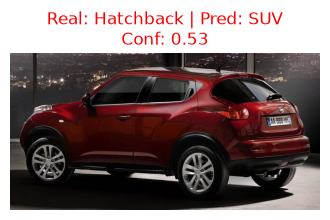

[Hatchback] 06059_Hyundai-Veloster-Hatchback-2012_jpg.rf.8dcf180365246abefa154445483c587e.jpg → Predicción: Coupe (confianza 0.76)


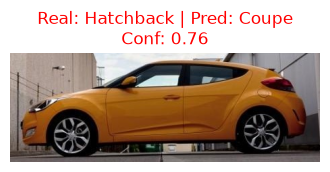

[Hatchback] 13_jpg.rf.af4b136c5e16ad9b57666f501e55bd06.jpg → Predicción: Sedan (confianza 0.92)


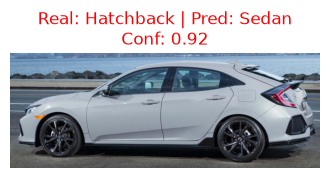

[Hatchback] 330_jpg.rf.49835e1ca8627b43a8017b4b2b548af2.jpg → Predicción: Sedan (confianza 0.60)


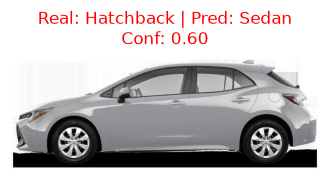

[Hatchback] 538_jpg.rf.6df0b0392afd3df23fc5928e20bdb92c.jpg → Predicción: Sedan (confianza 0.88)


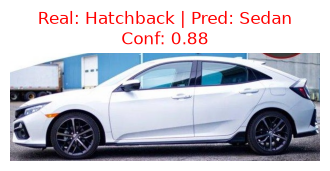

[Hatchback] d581b473-66ac-11eb-bb25-8c164571e025_jpg.rf.6cba7aece68d508854a9e09a88f236b8.jpg → Predicción: Sedan (confianza 0.69)


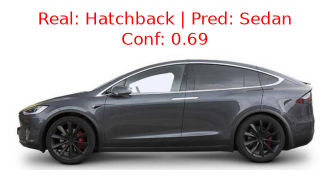

[Hatchback] d5824f90-66ac-11eb-818a-8c164571e025_jpg.rf.98b56f3dfc94f96462c142787d5c3ddd.jpg → Predicción: Sedan (confianza 0.94)


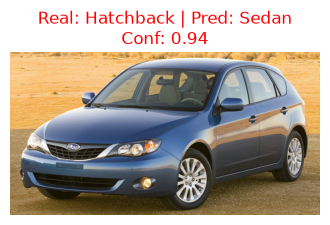

[Hatchback] d586227c-66ac-11eb-b36c-8c164571e025_jpg.rf.66f10d209c8b75a3e61fe0887fdb5087.jpg → Predicción: Sedan (confianza 0.54)


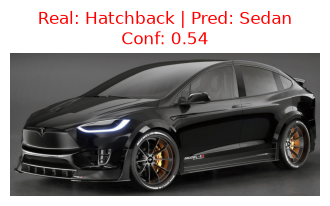

[Hatchback] Image_31_jpg.rf.8c6795212175e9c54d65c145620b9c6f.jpg → Predicción: Sedan (confianza 0.53)


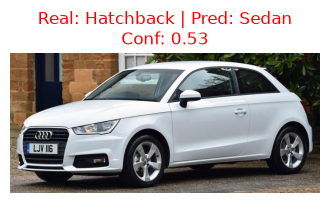

[Pick-Up] 02622_Dodge-Dakota-Crew-Cab-2010_jpg.rf.e71cef442dc126250c3ae4e2e24802e3.jpg → Predicción: Convertible (confianza 0.85)


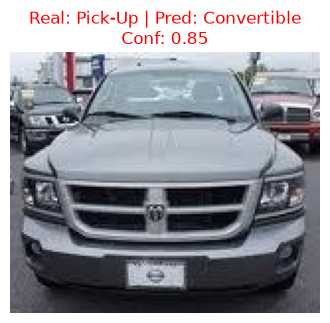

[Pick-Up] 04899_Chevrolet-Avalanche-Crew-Cab-2012_jpg.rf.c3be2a29fddae86015fd8f2e45015f3c.jpg → Predicción: SUV (confianza 0.69)


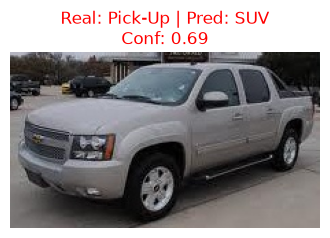

[Pick-Up] 163_jpg.rf.cca5405c5f6d989013375015e43670e9.jpg → Predicción: Convertible (confianza 0.46)


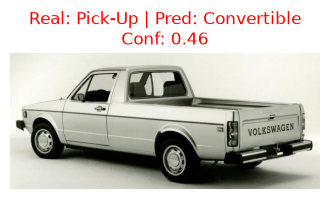

[Pick-Up] 202105062285557_jpg.rf.1d488de5eeedc9a3df13d0989dd2e831.jpg → Predicción: SUV (confianza 0.87)


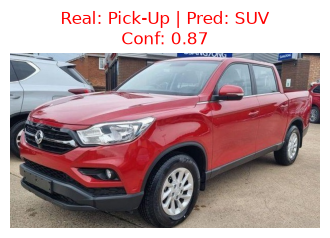

[Pick-Up] 78_jpg.rf.98762f743265e57acb684d0ad2c9a381.jpg → Predicción: SUV (confianza 0.63)


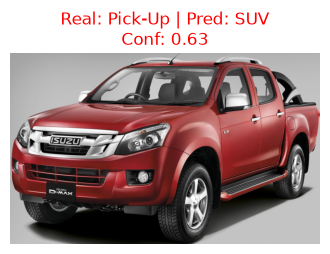

[Pick-Up] Image_137_jpg.rf.2291a2ae1c8f0c7bf466b9d9164cb4ae.jpg → Predicción: Hatchback (confianza 0.42)


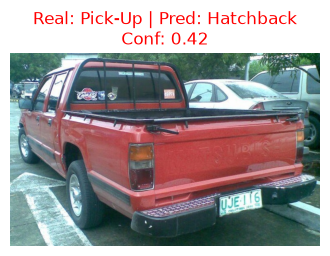

[Pick-Up] Image_27_jpg.rf.31e6e312b2e000e60788d4c4bde04b6d.jpg → Predicción: Convertible (confianza 0.51)


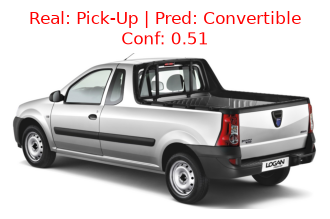

[Sedan] 00793_Audi-S4-Sedan-2007_jpg.rf.51cef7d5c5b02b4fb3f6b58e0b612dae.jpg → Predicción: Coupe (confianza 0.89)


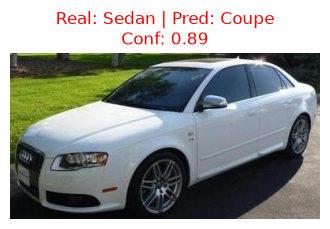

[Sedan] 01007_Hyundai-Genesis-Sedan-2012_jpg.rf.b272a1278028eac6ff664153e2d3337f.jpg → Predicción: Coupe (confianza 0.78)


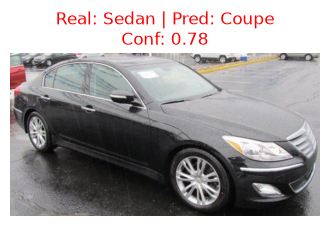

[Sedan] 03367_Audi-S6-Sedan-2011_jpg.rf.adae9cffd9ec959ca6f1b2a573ab2f62.jpg → Predicción: Coupe (confianza 1.00)


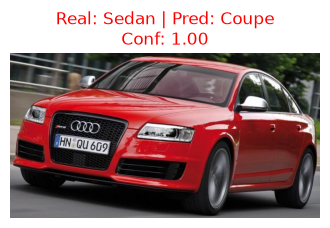

[Sedan] 03543_Audi-S6-Sedan-2011_jpg.rf.d4285cdfe7c46b6662bfe7114f3d2eea.jpg → Predicción: Coupe (confianza 0.65)


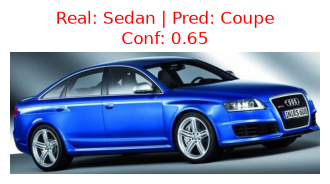

[Sedan] 03663_Hyundai-Genesis-Sedan-2012_jpg.rf.0dbde9b9e986fe8529570d27ccc05d3b.jpg → Predicción: Coupe (confianza 0.87)


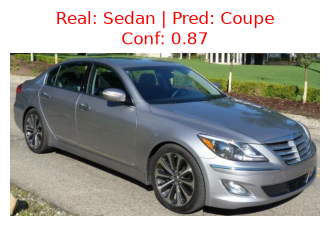

[Sedan] 03855_Audi-S4-Sedan-2007_jpg.rf.6c85dc03a752a0b23bdf227bbcb2e3be.jpg → Predicción: Hatchback (confianza 0.66)


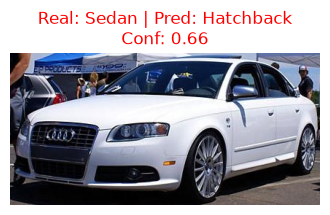

[Sedan] 193_jpg.rf.87db46f37852576c8c2729fe18930986.jpg → Predicción: Coupe (confianza 0.61)


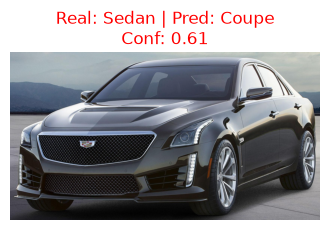

[Sedan] 392_jpg.rf.10c39b1a1164dc3fbaa8a164f16756f0.jpg → Predicción: Coupe (confianza 0.99)


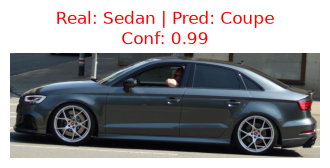

[Sedan] 44_jpg.rf.23b9e70b373e3ef5baf027fa4f0cfdc3.jpg → Predicción: Coupe (confianza 0.99)


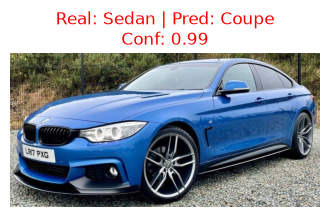

[Sedan] 466_jpg.rf.8d8a381b018b0b99d6acfb500da704fa.jpg → Predicción: Coupe (confianza 0.99)


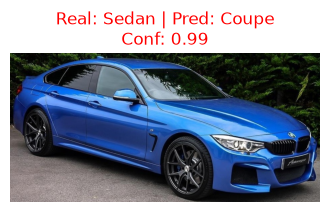

[Sedan] 538_jpg.rf.bfec0034a4bbf231f535d07a04ce2f9e.jpg → Predicción: Coupe (confianza 0.97)


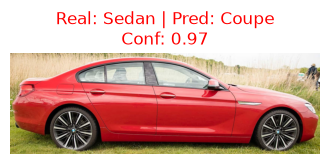

[Sedan] 8678256b-66b6-11eb-88a8-8c164571e025_jpg.rf.0d93553ac7238cfe3551702d0cf51c0d.jpg → Predicción: Hatchback (confianza 0.87)


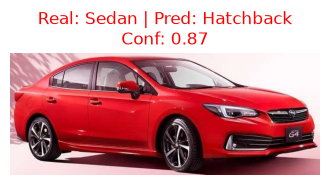

[Sedan] 8678e82e-66b6-11eb-a8a3-8c164571e025_jpg.rf.961a968024f05712f7aea473d80a5f11.jpg → Predicción: Coupe (confianza 0.65)


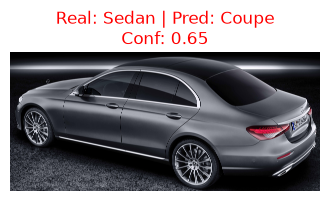

[Sedan] 86790f18-66b6-11eb-a977-8c164571e025_jpg.rf.b2509ee971ca8645e27912f6e5661b8c.jpg → Predicción: Coupe (confianza 0.98)


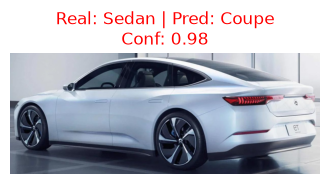

[Sedan] 867a6dbf-66b6-11eb-8bbb-8c164571e025_jpg.rf.46c576c446cd4a45b4e0da0dd0aabc3b.jpg → Predicción: Hatchback (confianza 0.91)


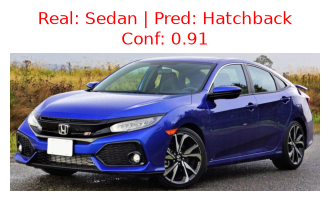

[Sedan] 867a94af-66b6-11eb-b3bd-8c164571e025_jpg.rf.08f34401f990aca0b1424f48317b326c.jpg → Predicción: Hatchback (confianza 0.95)


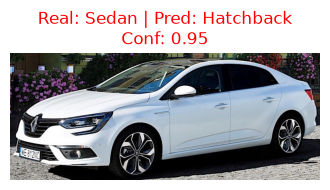

[Sedan] 87_jpg.rf.3f61a225af1fdc9f108f7a29ec0dbd77.jpg → Predicción: Coupe (confianza 0.66)


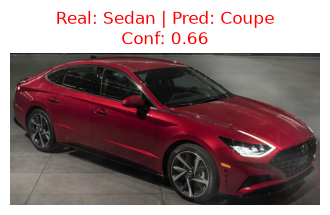

[Sedan] 91_jpg.rf.7b5e54bfbd87f407a8603b648a97cc33.jpg → Predicción: Coupe (confianza 0.82)


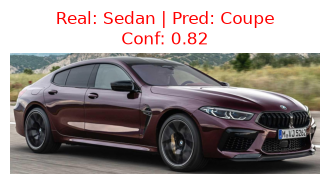

[SUV] 00409_Toyota-4Runner-SUV-2012_jpg.rf.559007d37c351113a72105daebc7a78a.jpg → Predicción: Pick-Up (confianza 0.71)


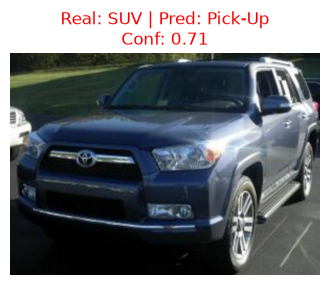

[SUV] 01050_Hyundai-Tucson-SUV-2012_jpg.rf.efc8c378a65a71b17cc75d405d3342f8.jpg → Predicción: Hatchback (confianza 0.67)


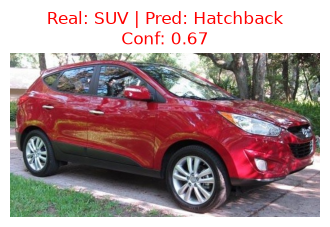

[SUV] 02319_Chevrolet-Tahoe-Hybrid-SUV-2012_jpg.rf.d6f6e9c25adfcf7498a4debabb46db87.jpg → Predicción: Pick-Up (confianza 0.90)


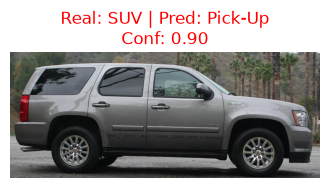

[SUV] 03837_Dodge-Journey-SUV-2012_jpg.rf.7524ece4819b9b98e7185a10749bbf1b.jpg → Predicción: Coupe (confianza 0.94)


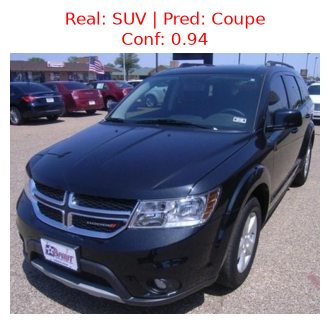

[SUV] 04947_Ford-Edge-SUV-2012_jpg.rf.6c1b3285ba356951dcba52c46fc404ca.jpg → Predicción: Hatchback (confianza 0.95)


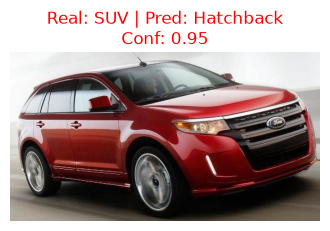

[SUV] 05071_Cadillac-SRX-SUV-2012_jpg.rf.8230d4fd2b82ba7777485d1a3f8dccc2.jpg → Predicción: Coupe (confianza 0.58)


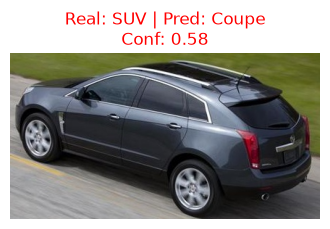

[SUV] 05880_Land-Rover-LR2-SUV-2012_jpg.rf.e6f89d022a2d1da7c875e457273c71bc.jpg → Predicción: Pick-Up (confianza 0.72)


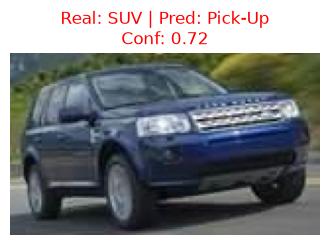

[SUV] 106_jpg.rf.3f876f0d95b54823eed10e9a5cc81a81.jpg → Predicción: Coupe (confianza 0.81)


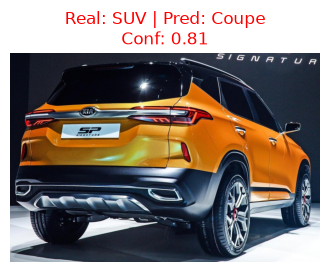

[SUV] 161_jpg.rf.af01205d2e47cdef215ef24b4fe6fc21.jpg → Predicción: Hatchback (confianza 0.91)


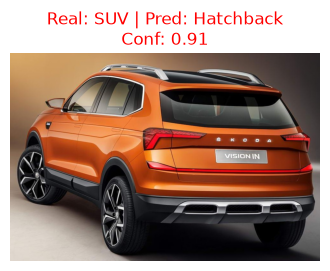

[SUV] 166_jpg.rf.efa3518ca3e50562108ee03a123d499e.jpg → Predicción: Pick-Up (confianza 0.59)


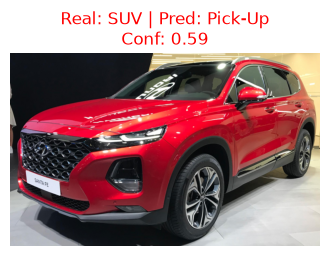

[SUV] 24_jpg.rf.49bbb634d8c10331c7ed2015dc4505ce.jpg → Predicción: Hatchback (confianza 0.68)


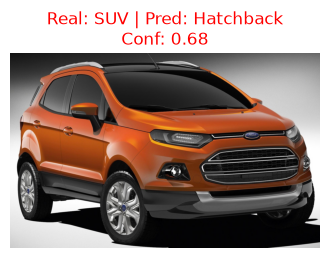

[SUV] 332_jpg.rf.253f1ffd3745f0b29d06308d3b433bca.jpg → Predicción: Coupe (confianza 0.52)


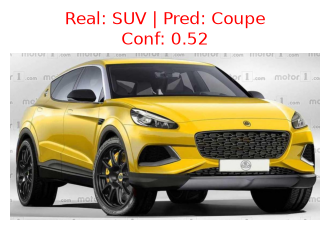

[SUV] 349_jpg.rf.401a8d6b4d2e5921f85e4c0fb64807ac.jpg → Predicción: Hatchback (confianza 0.98)


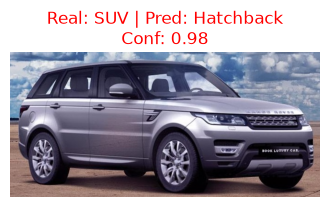

[SUV] Image_86_jpg.rf.080f77c37cb03a003c35ae2dd8257523.jpg → Predicción: Sedan (confianza 0.62)


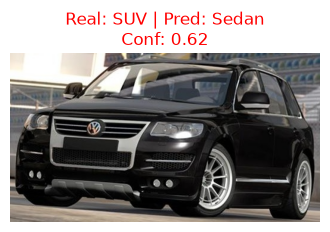

[VAN] 121_jpg.rf.66f2627045929e12e101e5b3fb59d05f.jpg → Predicción: Hatchback (confianza 0.53)


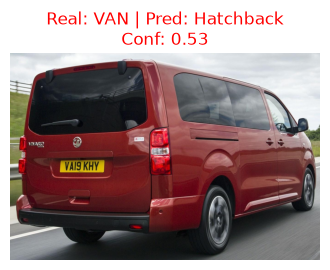

[VAN] 202103170241444_jpg.rf.34349f8352836893c586aaa639508d6c.jpg → Predicción: SUV (confianza 0.47)


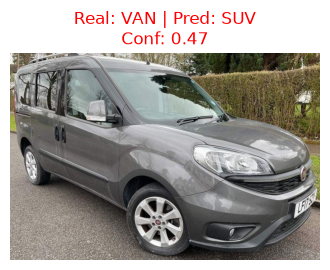

In [21]:
import os
import numpy as np
from PIL import Image
import pickle
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

# 1. Cargar modelo y label encoder
print("Cargando modelo y label encoder...")
modelo = load_model("modelo_cars_v4.keras")

with open("labelencoder_v4.pkl", "rb") as f:
    labelencoder = pickle.load(f)

# 2. Ruta de prueba
ruta_nuevos = r"Cars_Body_Type/test"
img_size = (150, 150)
EXTENSIONES = ('.jpg', '.jpeg', '.png')

# 3. Función: predice todo, pero solo muestra las incorrectas
def predecir_y_mostrar_errores(ruta_raiz, modelo, labelencoder, img_size=img_size, max_mostrar=None):
    resultados = []   # (archivo, clase_real, clase_pred, correcta)
    errores = []      # (ruta, clase_real, clase_pred)

    if not os.path.exists(ruta_raiz):
        print(f"Error: La ruta '{ruta_raiz}' no existe.")
        return resultados

    # Recolectar rutas de imágenes
    rutas = []
    for root, dirs, files in os.walk(ruta_raiz):
        for archivo in files:
            if archivo.lower().endswith(EXTENSIONES):
                rutas.append(os.path.join(root, archivo))

    if not rutas:
        print(f"No se encontraron imágenes válidas en '{ruta_raiz}'.")
        return resultados

    print(f"Se encontraron {len(rutas)} imágenes. Procesando...")

    for ruta in rutas:
        clase_real = os.path.basename(os.path.dirname(ruta))

        # Cargar y preprocesar (convert('RGB') evita fallos con PNG/escala de grises)
        img = Image.open(ruta).convert("RGB")
        img_array = np.array(img.resize(img_size)) / 255.0
        img_array = np.expand_dims(img_array, axis=0)

        # Predicción
        pred = modelo.predict(img_array, verbose=0)
        clase_pred = labelencoder.inverse_transform(np.argmax(pred, axis=1))[0]

        correcta = str(clase_pred) == str(clase_real)
        resultados.append((os.path.basename(ruta), clase_real, clase_pred, correcta))

        if not correcta:
            errores.append((ruta, clase_real, clase_pred, float(np.max(pred))))

    # 4. Resumen general
    total = len(resultados)
    aciertos = sum(r[3] for r in resultados)
    print(f"\n===== RESUMEN =====")
    print(f"Total: {total} | Aciertos: {aciertos} | Errores: {len(errores)}")
    print(f"Accuracy: {aciertos / total:.4f}")

    # Errores por clase real
    print("\nErrores por clase real:")
    clases = sorted({r[1] for r in resultados})
    for c in clases:
        tot_c = sum(1 for r in resultados if r[1] == c)
        err_c = sum(1 for r in resultados if r[1] == c and not r[3])
        print(f"  {c}: {err_c}/{tot_c} errores ({err_c / tot_c:.1%})")

    # 5. Mostrar solo las mal clasificadas
    if not errores:
        print("\nNo hubo errores de clasificación.")
        return resultados

    a_mostrar = errores if max_mostrar is None else errores[:max_mostrar]
    print(f"\nMostrando {len(a_mostrar)} de {len(errores)} imágenes mal clasificadas...")

    for ruta, clase_real, clase_pred, confianza in a_mostrar:
        print(f"[{clase_real}] {os.path.basename(ruta)} → Predicción: {clase_pred} (confianza {confianza:.2f})")
        plt.figure(figsize=(4, 4))
        plt.imshow(Image.open(ruta).convert("RGB"))
        plt.title(f"Real: {clase_real} | Pred: {clase_pred}\nConf: {confianza:.2f}", color="red")
        plt.axis("off")
        plt.show()

    return resultados

# Ejecutar
resultados = predecir_y_mostrar_errores(ruta_nuevos, modelo, labelencoder)

Mal clasificadas: 44 de 802 (5.5%)
Bien clasificadas: 758 de 802 (94.5%)
             total  aciertos  errores  % error
real                                          
Coupe           79        69       10     12.7
Hatchback       99        88       11     11.1
SUV            125       115       10      8.0
Sedan          109       102        7      6.4
Pick-Up        110       108        2      1.8
Convertible    174       171        3      1.7
VAN            106       105        1      0.9

Confusiones más frecuentes:
real         pred       
Hatchback    Sedan          7
Sedan        Coupe          6
Coupe        Sedan          6
SUV          Hatchback      5
Convertible  Coupe          3
Coupe        Convertible    3
SUV          Sedan          2
             Pick-Up        2
Hatchback    SUV            2
Pick-Up      Convertible    1
Name: cantidad, dtype: int64


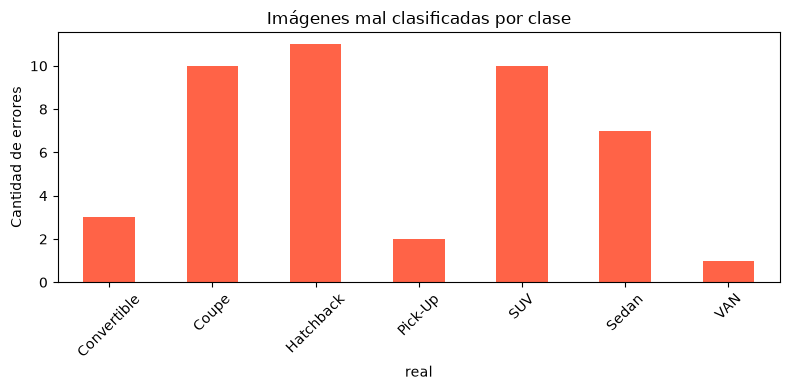

In [ ]:
import pandas as pd

df = pd.DataFrame(resultados, columns=["archivo", "real", "pred", "correcta"])

total = len(df)
errores = (~df["correcta"]).sum()
print(f"Mal clasificadas: {errores} de {total} ({errores/total:.1%})")
print(f"Bien clasificadas: {total - errores} de {total} ({(total-errores)/total:.1%})")

# Errores por clase real
resumen = df.groupby("real")["correcta"].agg(
    total="count",
    aciertos="sum"
)
resumen["errores"] = resumen["total"] - resumen["aciertos"]
resumen["% error"] = (resumen["errores"] / resumen["total"] * 100).round(1)
print(resumen.sort_values("% error", ascending=False))

# Qué clases se confunden entre sí (real -> predicha)
confusiones = (
    df[~df["correcta"]]
    .groupby(["real", "pred"])
    .size()
    .sort_values(ascending=False)
    .rename("cantidad")
)
print("\nConfusiones más frecuentes:")
print(confusiones.head(10))

# Gráfico de errores por clase
resumen["errores"].plot(kind="bar", color="tomato", figsize=(8, 4))
plt.title("Imágenes mal clasificadas por clase")
plt.ylabel("Cantidad de errores")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# import os
# import numpy as np
# from PIL import Image
# import pickle
# from tensorflow.keras.models import load_model
# import matplotlib.pyplot as plt

# # 1. Cargar modelo y label encoder
# print("Cargando modelo y label encoder...")
# modelo = load_model("modelo_cars.keras")

# with open("labelencoder.pkl", "rb") as f:
#     labelencoder = pickle.load(f)

# # 2. Definir ruta de prueba
# ruta_nuevos = r"Cars_Body_Type/test"
# img_size = (150, 150)

# # 3. Función actualizada para buscar imágenes dentro de subcarpetas
# def predecir_y_mostrar_carpetas(ruta_raiz, modelo, labelencoder, img_size=img_size):
#     resultados = []
    
#     if not os.path.exists(ruta_raiz):
#         print(f"Error: La ruta '{ruta_raiz}' no existe.")
#         return resultados

#     # Usamos os.walk para recorrer la carpeta principal y todas sus subcarpetas
#     total_imagenes = 0
#     for root, dirs, files in os.walk(ruta_raiz):
#         for archivo in files:
#             if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
#                 total_imagenes += 1

#     if total_imagenes == 0:
#         print(f"No se encontraron imágenes válidas en '{ruta_raiz}' ni en sus subcarpetas.")
#         return resultados

#     print(f"Se encontraron {total_imagenes} imágenes. Procesando...")

#     for root, dirs, files in os.walk(ruta_raiz):
#         for archivo in files:
#             if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):
#                 ruta = os.path.join(root, archivo)
#                 # Opcional: obtener la clase real basada en el nombre de la subcarpeta
#                 clase_real = os.path.basename(root)

#                 # Cargar y preprocesar la imagen
#                 img = Image.open(ruta)
#                 img_resized = img.resize(img_size)
                
#                 img_array = np.array(img_resized) / 255.0
#                 img_array = np.expand_dims(img_array, axis=0)

#                 # Predicción
#                 pred = modelo.predict(img_array, verbose=0)
#                 clase_pred = np.argmax(pred, axis=1)

#                 # Convertir a etiqueta original
#                 etiqueta = labelencoder.inverse_transform(clase_pred)
                
#                 resultados.append((archivo, etiqueta[0]))

#                 # Imprimir resultado en consola (mostrando la carpeta/clase real y la predicha)
#                 print(f"[{clase_real}] {archivo} → Predicción: {etiqueta[0]}")

#                 # Mostrar imagen con matplotlib
#                 plt.figure(figsize=(4, 4))
#                 plt.imshow(img)
#                 plt.title(f"Real: {clase_real} | Pred: {etiqueta[0]}")
#                 plt.axis("off")
#                 plt.show()

#     return resultados

# # Ejecutar el proceso actualizado
# resultados = predecir_y_mostrar_carpetas(ruta_nuevos, modelo, labelencoder)